##**8.3 하이퍼파라미터를 이용한 성능 최적화**

- 배치 정규화
- 드롭아웃
- 조기종료

###**8.3.1 배치 정규화를 이용한 성능 최적화**

**정규화**

: 데이터 범위를 사용자가 원하는 범위로 제한하는 것

> 각 특성 범위를 조정한다는 의미로 특성 스케일링이라고도 함

- MinMaxScaler() 기법을 사용

**규제화**

: 모델 복잡도를 줄이기 위해 제약을 두는 방법

- 이때 제약은 데이터가 네트워크에 들어가기 전에 필터를 적용한 것

[규제를 이용하여 모델 복잡도를 줄이는 방법]

- 드롭아웃
- 조기 종료

**표준화**

: 기존 데이터를 평균은 0, 표준편자는 1인 형태의 데이터로 만드는 방법

- 다른 표현으로 '표준화 스칼라' 혹은 'z-스코어 정규화'라고도 함
- 평균을 기준으로 얼마나 떨어져 있는지 살펴볼 때 사용. 보통 데이터 분포가 가우시안 분포를 따를 때 유용

**배치 정규화**

: 기울기 소멸이나 기울기 폭발 같은 문제를 해결하기 위한 방법

- 기울기 소멸: 오차 정보를 역전파시키는 과정에서 기울기가 급격히 0에 가까워져 학습이 되지 않는 현상
- 기울기 폭발: 학습 과정에서 기울기가 급격히 커지는 현상
- 위 문제가 발생하는 원인은 내부 공변량 변화 때문. 이것은 네트워크의 각 층마다 활성화 함수가 적용되면서 입력 값들의 분포가 계속 바뀌는 현상을 의미.

> 따라서 분산된 분포를 정규분포로 만들기 위해 표준화와 유사한 방식을 미니 배치에 적용하여 평균은 0, 표준편차는 1로 유지하도록 함

1. 미니 배치 평균을 구하기
2. 미니 배치의 분산과 표준편차를 구하기
3. 정규화를 수행하기
4. 스케일을 조정하기

- 매 단계마다 활성화 함수를 거치면서 데이터셋 분포가 일정해지기 때문에 속도를 향상시킬 수 있음.
- 반면, 배치 크기가 작을 때는 정규화 값이 기존 값과 다른 방향으로 훈련될 수 있음
- RNN은 네트워크 계측별로 미니 정규화를 적용해야 하기 때문에 모델이 더 복잡해지면서 비효율적일 수 있음

###**8.3.2 드롭아웃을 이용한 성능 최적화**

- 과적합은 훈련 데이터셋을 과하게 학습하는 것을 의미
- 훈련 데이터셋에 대해 훈련을 계속한다면 오류는 줄어들지만 테스트 데이터셋에 대한 오류는 어느 순간부터 증가
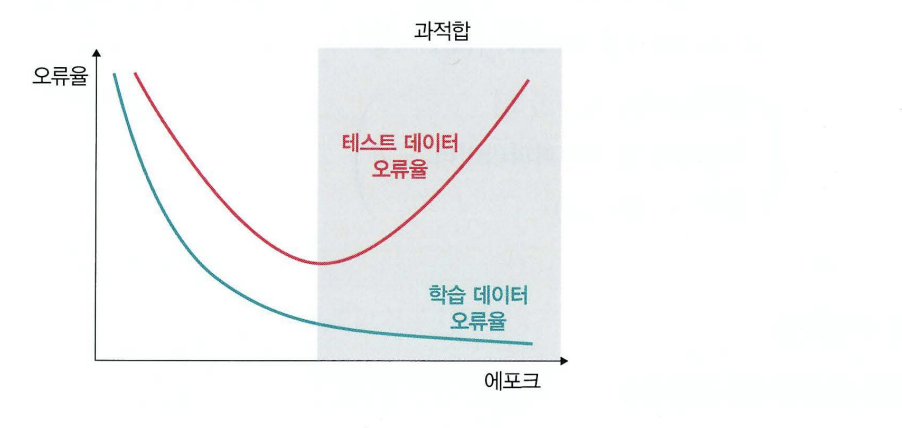



**드롭아웃**: 훈련할 때 일정 비율의 뉴련만 사용하고, 나머지 뉴런에 해당하는 가중치는 업데이트하지 않는 방법

- 노드를 임의로 끄면서 학습하는 방법으로, 은닉층에 배치된 노드 중 일부를 임의로 끄면서 학습
- 꺼진 노드는 신호를 전달하지 않으므로 지나친 학습을 방지하는 효과가 생김

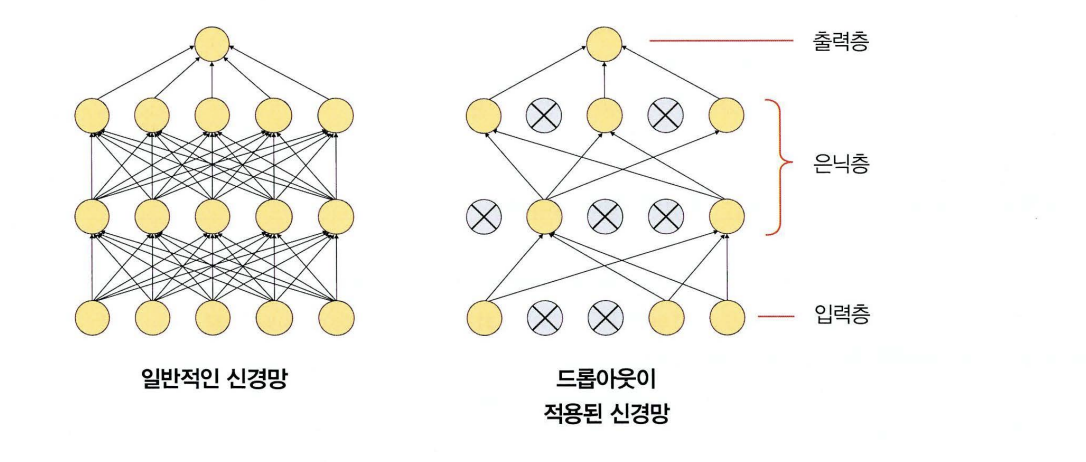

- 일부 노드들은 비활성화되고 남은 노드들로 신호가 연결되는 신경망 형태를 띔
- 어떤 노드를 비활성화할지는 학습할 때마다 무작위로 선정되며, 테스트 데이터로 평가할 때는 노드들을 모두 사용하여 출력하되 노드 삭제 비율을 곱해 성능을 평가
- 드롭아웃을 사용하면 훈련 시간이 길어지는 단점이 있음

In [ ]:
# 라이브러리 호출
import torch
import matplotlib.pyplot as plt
import numpy as np

import torchvision
import torchvision.transforms as transforms

import torch.nn as nn
import torch.optim as optim

In [ ]:
# 데이터셋 내려받기 (FashionMNIST 데이터셋)
trainset = torchvision.datasets.FashionMNIST(
    root = './data',
    train = True,
    download = True,
    transform = transforms.ToTensor()
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 170kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.14MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 28.7MB/s]


In [ ]:
# 데이터셋을 메모리로 가져오기
batch_size = 4
trainloader = torch.utils.data.DataLoader(trainset, batch_size = batch_size, shuffle = True)

- trainloader 변수가 호출될 때 메모리로 가져오게 됨

In [ ]:
# 데이터셋 분리
dataiter = iter(trainloader)
images, labels = next(dataiter)

print(images.shape)
print(images[0].shape)
print(labels[0].item())

torch.Size([4, 1, 28, 28])
torch.Size([1, 28, 28])
2


torch.Size([4, 1, 28, 28])

- 4: 한 번의 배치 크기로 몇 개의 데이터를 가져오는지 의미
- 1: 채널을 의미하는 것으로 흑백 이미지는 1, 컬러 이미지는 3을 출력
- 28x28: 픽셀 크기의 이미지

In [ ]:
# 이미지 데이터를 출력하기 위한 전처리
def imshow(img, title):
    plt.figure(figsize = (batch_size * 4, 4)) # 출력할 개별 이미지의 크기 저장
    plt.axis('off')
    plt.imshow(np.transpose(img, (1, 2, 0)))
    plt.title(title)
    plt.show()

- 기본적으로 파이토치는 이미지 데이터셋을 [배치 크기, 채널, 너비, 높이] 순서대로 저장. 하지만 이를 맷플롯립으로 출력하기 위해서는 이미지가 [너비, 높이, 채널] 형태여야 함
- 즉, 데이터의 형태 변경이 필요한데, 이때 사용할 수 있는 것이 넘파이의 transpose()

In [ ]:
# 이미지 데이터 출력 함수
def show_batch_images(dataloader):
  images, labels = next(iter(dataloader)) # 이미지의 크기는 (4,28,28,1(배치 크기, 높이, 너비, 채널))이 됩니다.

  img = torchvision.utils.make_grid(images) # 좌표에 이미지 픽셀을 대응시켜 그리드 형태로 출력합니다.
  imshow(img, title=[str(x.item()) for x in labels]) # imshow 함수를 사용함으로써 데이터의 형태는 (채널, 높이, 너비)에서 (높이, 너비, 채널)로 변경됩니다.

  return images, labels

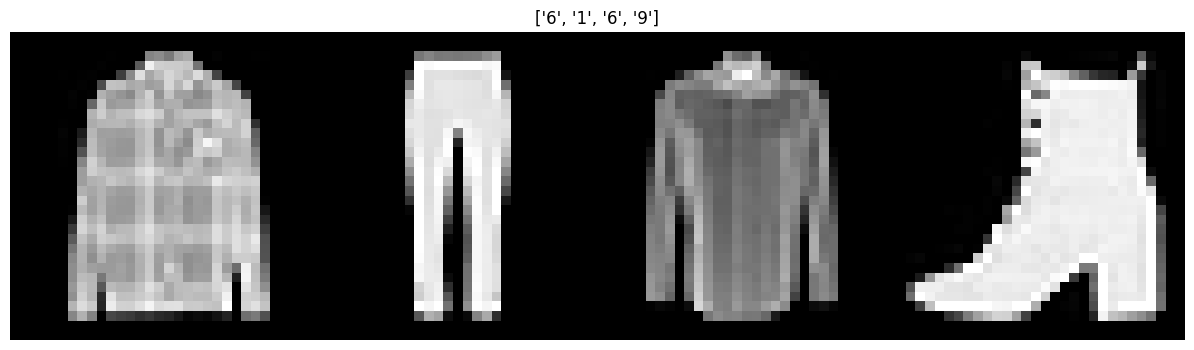

In [ ]:
# 이미지 출력
images, labels = show_batch_images(trainloader)

In [ ]:
# 배치 정규화가 적용되지 않은 네트워크
class NormalNet(nn.Module):
  def __init__(self):
    super(NormalNet, self).__init__()
    self.classifier = nn.Sequential(
        nn.Linear(784, 48), # (28,28) 크기의 이미지로 입력은 784(28x28) 크기가 됩니다.
        nn.ReLU(),
        nn.Linear(48, 24),
        nn.ReLU(),
        nn.Linear(24, 10) # FashonMNIST의 클래스는 총 열 개
    ) # nn.Sequential을 사용하면 forward() 함수에서 계층별로 가독성 있게 코드 구현이 가능

  def forward(self, x):
    x = x.view(x.size(0), -1)
    x = self.classifier(x) # nn.Sequential에서 정의한 계층 호출
    return x

In [ ]:
# 배치 정규화가 포함된 네트워크
class BNNet(nn.Module):
  def __init__(self):
    super(BNNet, self).__init__()
    self.classifier = nn.Sequential(
        nn.Linear(784, 48),
        nn.BatchNorm1d(48),
        nn.ReLU(),
        nn.Linear(48, 24),
        nn.BatchNorm1d(24),
        nn.ReLU(),
        nn.Linear(24, 10)
    )

  def forward(self, x):
    x = x.view(x.size(0), -1)
    x = self.classifier(x)
    return x

nn.BatchNorm1d(48)

- 배치 정규화가 적용되는 부분. BatchNorm1d에서 사용되는 파라미터는 특성 개수로 이전 계층의 출력 채널이 됨

> 배치 정규화를 사용하는 이유는 은닉층에서 학습이 진행될 때마다 입력 분포가 변하면서 가중치가 엉뚱한 방향으로 갱신되는 문제가 종종 발생하기 때문. 즉, 신경망의 층이 깊어질수록 학습할 때 가정했던 입력 분포가 변화하여 엉뚱한 학습이 진행될 수 있는데 배치 정규화를 적용해 입력 분포를 고르게 맞추어 줄 수 있음

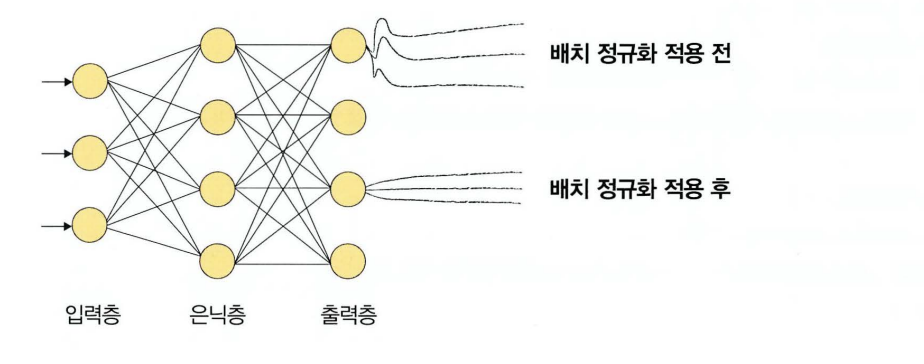

- 배치 정규화는 다음과 같은 위치에 놓여야 함

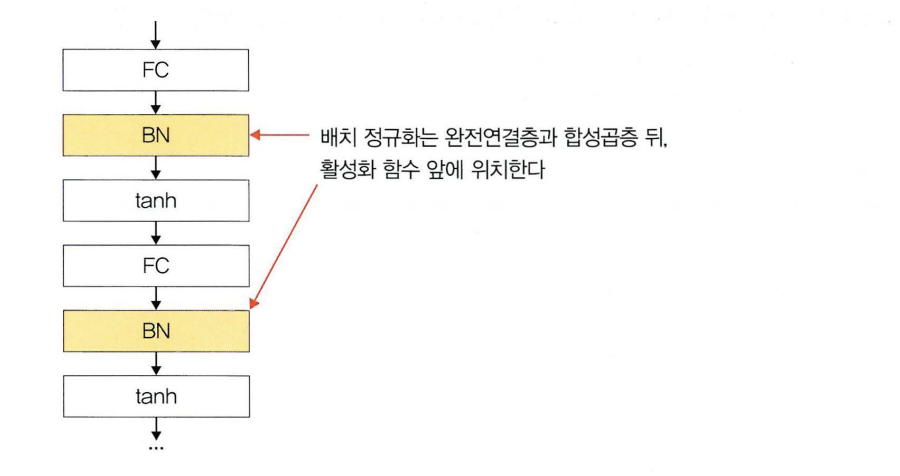

In [ ]:
# 배치 정규화가 적용되지 않은 모델 선언
model = NormalNet()
print(model)

NormalNet(
  (classifier): Sequential(
    (0): Linear(in_features=784, out_features=48, bias=True)
    (1): ReLU()
    (2): Linear(in_features=48, out_features=24, bias=True)
    (3): ReLU()
    (4): Linear(in_features=24, out_features=10, bias=True)
  )
)


In [ ]:
# 배치 정규화가 적용된 모델 선언
model_bn = BNNet()
print(model_bn)

BNNet(
  (classifier): Sequential(
    (0): Linear(in_features=784, out_features=48, bias=True)
    (1): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=48, out_features=24, bias=True)
    (4): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=24, out_features=10, bias=True)
  )
)


In [ ]:
# 데이터셋 메모리로 불러오기
batch_size = 512
trainloader = torch.utils.data.DataLoader(trainset, batch_size = batch_size, shuffle = True)

In [ ]:
# 옵티마이저, 손실 함수 지정
loss_fn = nn.CrossEntropyLoss()
opt = optim.SGD(model.parameters(), lr=0.01)
opt_bn = optim.SGD(model_bn.parameters(), lr=0.01)

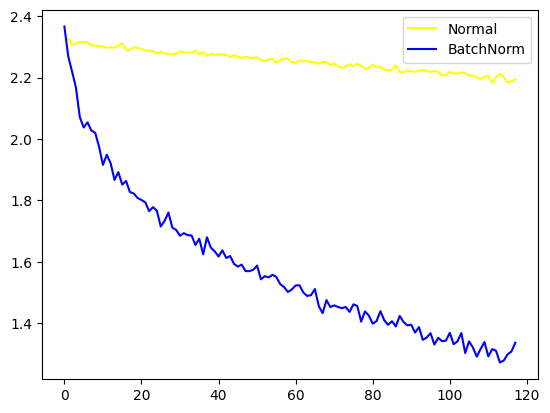

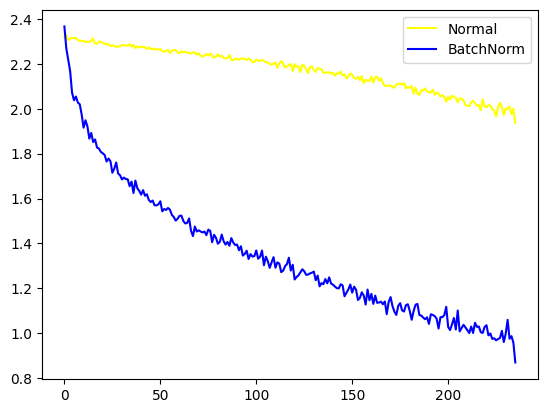

In [ ]:
# 모델 학습
loss_arr = []
loss_bn_arr = []
max_epochs = 2

for epoch in range(max_epochs):
  for i, data in enumerate(trainloader, 0):
    inputs, labels = data
    opt.zero_grad() # 배치 정규화가 적용되지 않은 모델의 학습
    outputs = model(inputs)
    loss = loss_fn(outputs, labels)
    loss.backward()
    opt.step()

    opt_bn.zero_grad() # 배치 정규화가 적용된 모델의 학습
    outputs_bn = model_bn(inputs)
    loss_bn = loss_fn(outputs_bn, labels)
    loss_bn.backward()
    opt_bn.step()

    loss_arr.append(loss.item())
    loss_bn_arr.append(loss_bn.item())

  plt.plot(loss_arr, 'yellow', label='Normal')
  plt.plot(loss_bn_arr, 'blue', label='BatchNorm')
  plt.legend()
  plt.show()

- 파란색 그래프: 배치 정규화 적용된 모델
- 노란색 그래프: 적용되지 않은 모델

- 둘 다 시간이 지날수록 오차가 줄어들지만, 오차가 줄어드는 범위 및 값의 차이는 명백함. 배치 정규화가 적용된 모델의 경우 더 낮은 값으로 안정적인 범위 내에서 줄어들고 있는 것을 확인할 수 있음

In [ ]:
# 데이터셋의 분포를 출력하기 위한 전처리
N = 50
noise = 0.3

x_train = torch.unsqueeze(torch.linspace(-1, 1, N), 1)
y_train = x_train + noise * torch.normal(torch.zeros(N, 1), torch.ones(N, 1))

x_test = torch.unsqueeze(torch.linspace(-1, 1, N), 1)
y_test = x_test + noise * torch.normal(torch.zeros(N, 1), torch.ones(N, 1))

- torch.linspace: 주어진 범위에서 균등한 값을 갖는 텐서를 만들기 위해 사용

```
torch.linspace(-1, 1, N)
```
> 의미는 -1 ~ 1의 범위에서 N개의 균등한 값을 갖는 텐서를 생성하겠다는 것

- torch.unsqueeze: 차원을 늘리기 위해 사용

```
torch.unsqueeze(torch.linspace(-1, 1, N), 1)
```
> 의미는 torch.linspace(-1, 1, N) 텐서의 첫 번째 자리에 차원을 증가시키겠다는 것

- torch.normal(평균, 표준편차): 정규분포로부터 무작위 표본 추출을 위해 사용
- torch.zeros: 0 값을 갖는 Nx1 텐서 생성
- torch.ones: 1 값을 갖는 Nx1 텐서 생성




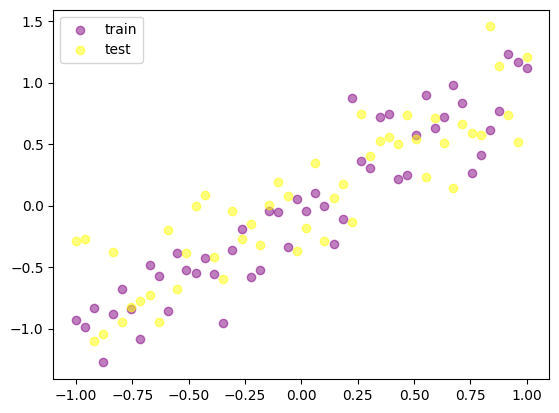

In [ ]:
# 데이터 분포를 그래프로 출력
plt.scatter(x_train.data.numpy(), y_train.data.numpy(), c = 'purple',
            alpha = 0.5, label = 'train')
plt.scatter(x_test.data.numpy(), y_test.data.numpy(), c = 'yellow',
            alpha = 0.5, label = 'test')
plt.legend()
plt.show()

In [ ]:
# 드롭아웃을 위한 모델 생성
N_h = 100
model = torch.nn.Sequential(
    torch.nn.Linear(1, N_h),
    torch.nn.ReLU(),
    torch.nn.Dropout(p = 0.5),
    torch.nn.Linear(N_h, 1),
) # 드롭아웃이 적용되지 않은 모델

model_dropout = torch.nn.Sequential(
    torch.nn.Linear(1, N_h),
    torch.nn.Dropout(0.2), # 드롭아웃 적용
    torch.nn.ReLU(),
    torch.nn.Linear(N_h, N_h),
    torch.nn.Dropout(0.2),
    torch.nn.ReLU(),
    torch.nn.Linear(N_h, 1),
) # 드롭아웃이 적용된 모델

In [ ]:
# 옵티마이저와 손실 함수 지정
opt = torch.optim.Adam(model.parameters(), lr = 0.01)
opt_dropout = torch.optim.Adam(model_dropout.parameters(), lr = 0.01)
loss_fn = torch.nn.MSELoss()

/tmp/ipykernel_17605/1586658583.py:35: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  plt.title('Epoch %d, Loss=%0.4f, Loss with dropout=%0.4f' %


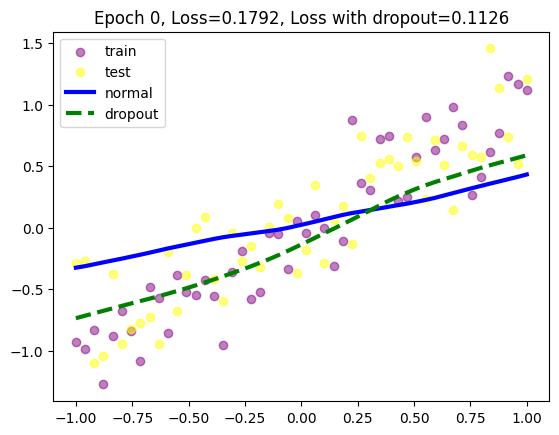

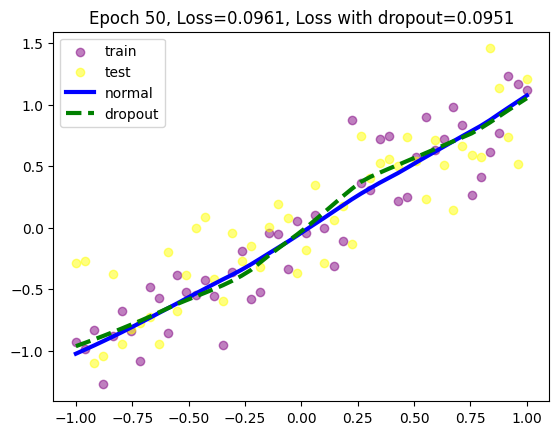

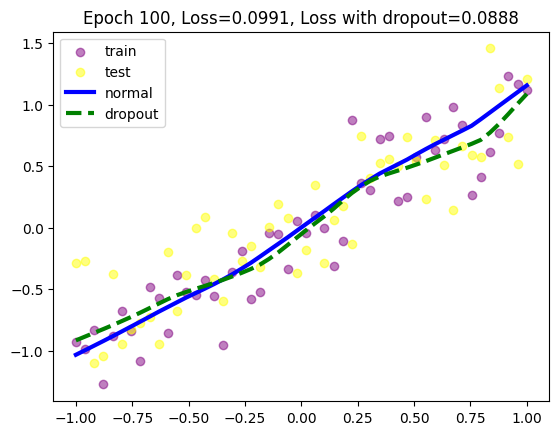

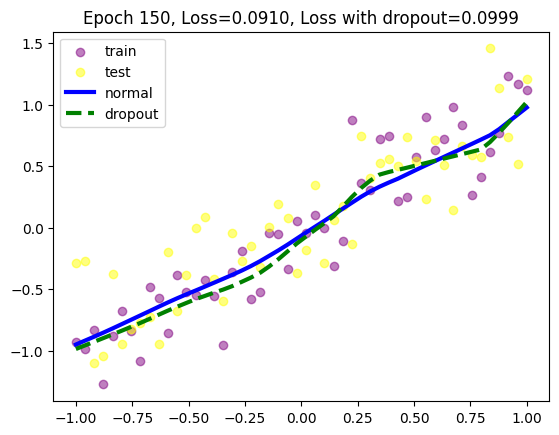

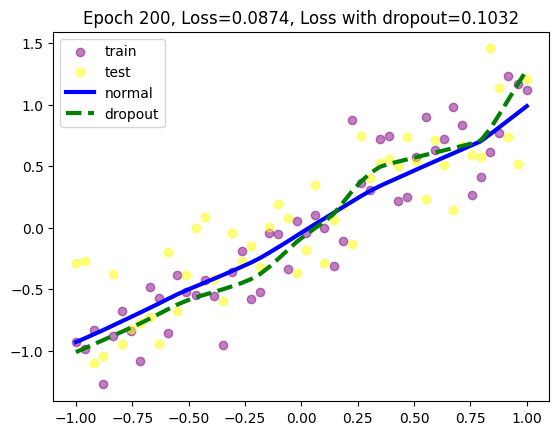

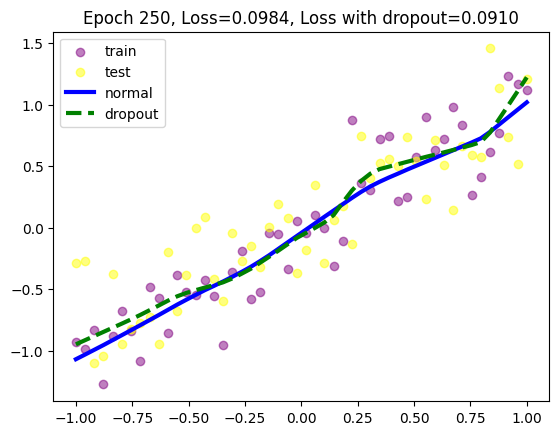

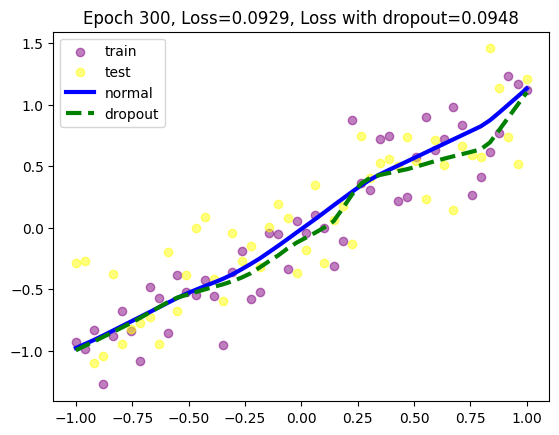

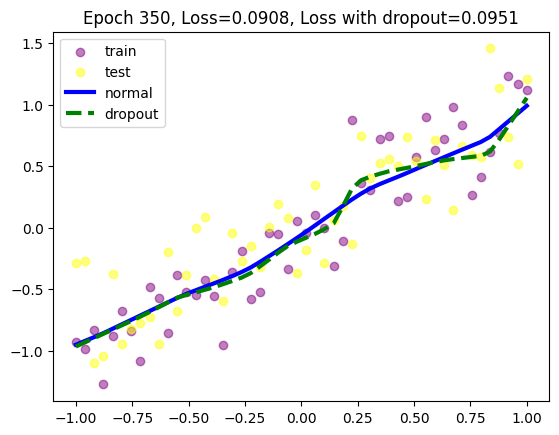

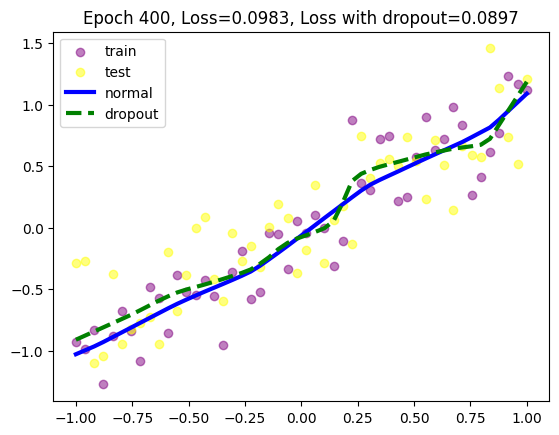

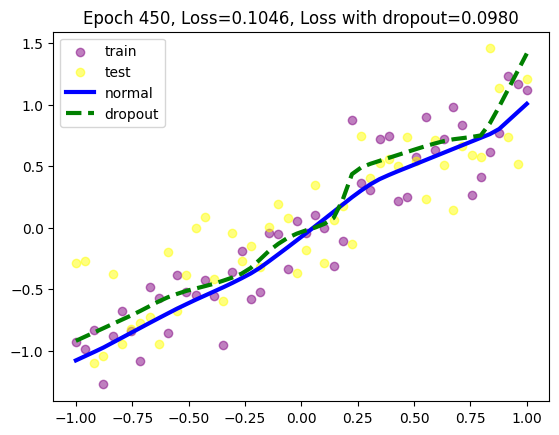

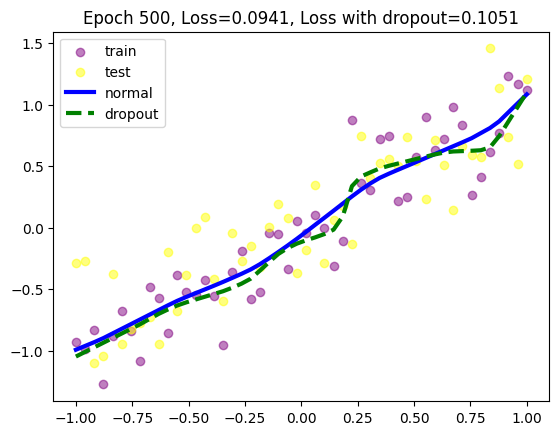

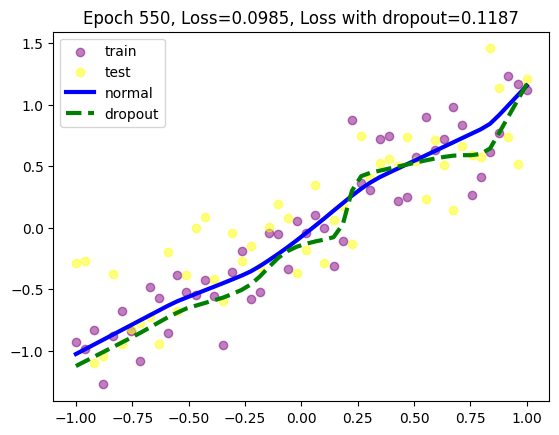

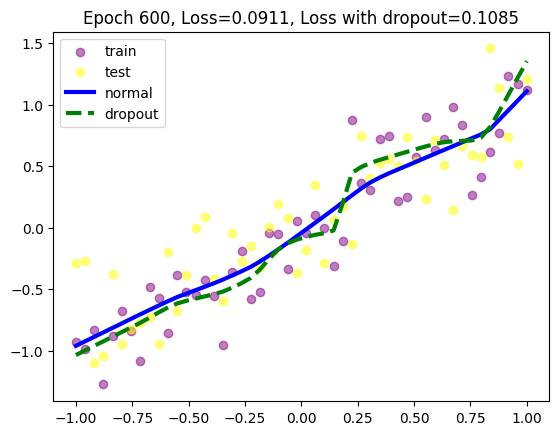

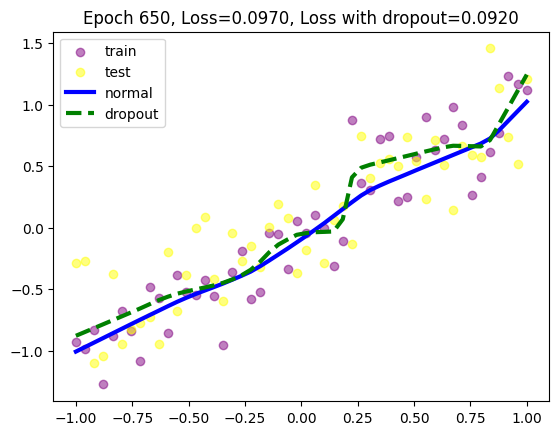

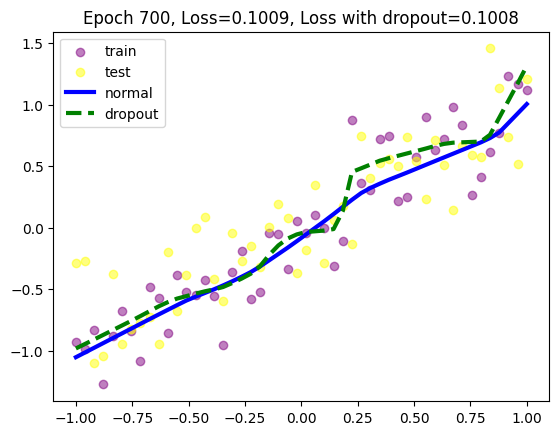

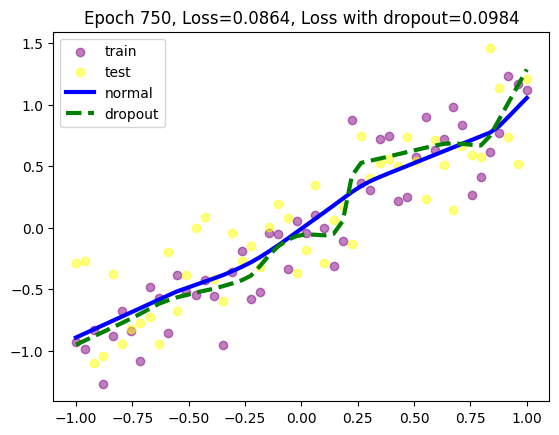

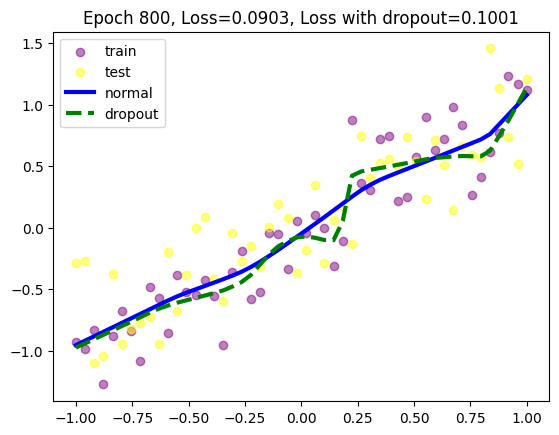

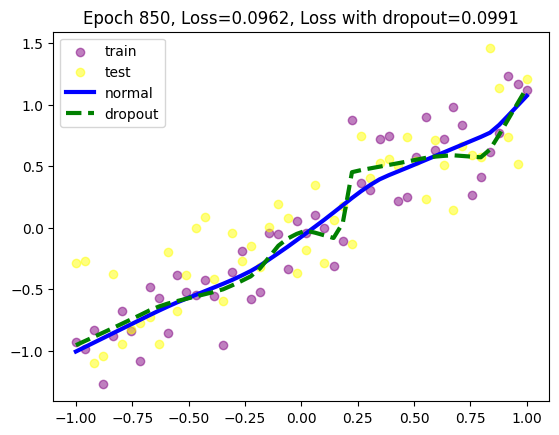

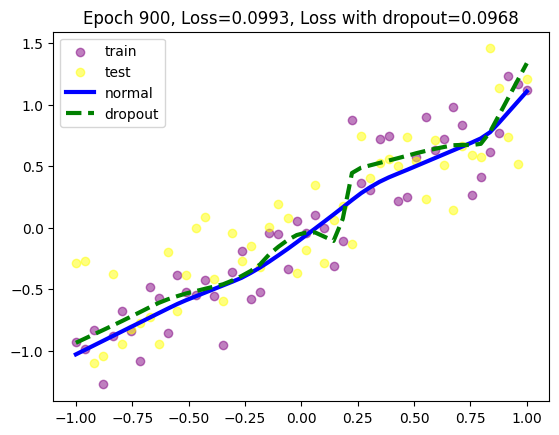

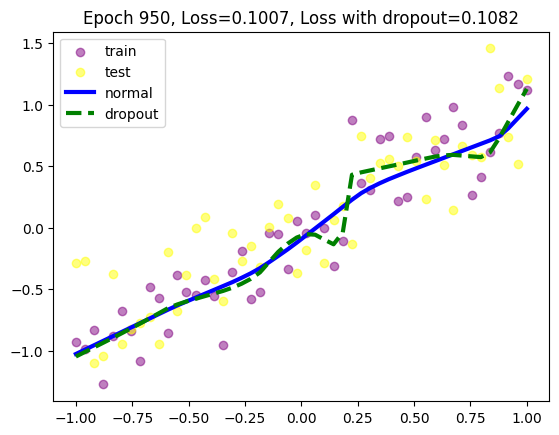

In [ ]:
# 모델 학습
max_epochs = 1000
for epoch in range(max_epochs):
  pred = model(x_train) # 드롭아웃이 적용되지 않은 모델 학습
  loss = loss_fn(pred, y_train)
  opt.zero_grad()
  loss.backward()
  opt.step()

  pred_dropout = model_dropout(x_train) # 드롭아웃이 적용된 모델 학습
  loss_dropout = loss_fn(pred_dropout, y_train)
  opt_dropout.zero_grad()
  loss_dropout.backward()
  opt_dropout.step()

  if epoch % 50 == 0: # epoch를 50으로 나눈 나머지가 0이면 다음 진

    model.eval()
    model_dropout.eval()

    test_pred = model(x_test)
    test_loss = loss_fn(test_pred, y_test)

    test_pred_dropout = model_dropout(x_test)
    test_loss_dropout = loss_fn(test_pred_dropout, y_test)

    plt.scatter(x_train.data.numpy(), y_train.data.numpy(), c='purple',
                alpha=0.5, label='train')
    plt.scatter(x_test.data.numpy(), y_test.data.numpy(), c='yellow',
                alpha=0.5, label='test')
    plt.plot(x_test.data.numpy(), test_pred.data.numpy(), 'b-', lw=3,
             label='normal') # 파란색 실선으로 x축은 테스트 데이터셋, y축은 드롭아웃이 적용되지 않은 모델의 결과를 그래프로 출력
    plt.plot(x_test.data.numpy(), test_pred_dropout.data.numpy(), 'g--', lw=3,
             label='dropout') # 초록색 점선으로 x축은 테스트 데이터셋. y축은 드롭아웃이 적용된 모델의 결과를 그래프로 출력
    plt.title('Epoch %d, Loss=%0.4f, Loss with dropout=%0.4f' %
              (epoch, test_loss, test_loss_dropout)) # 에포크, 드롭아웃이 적용되지 않은 모델의 오차, 드롭아웃이 적용된 모델의 오차를 타이틀로 출력
    plt.legend()
    model.train()
    model_dropout.train()
    plt.pause(0.05)

- 전반적으로 오차가 줄어드는 범위는 크지 않으나, 드롭아웃을 적용했을 떄의 오차가 더 낮은 것을 확인할 수 있음

<br>

###**8.3.3 조기 종료를 이용한 성능 최적화**

: 뉴럴 네트워크가 과적합을 회피하는 규제 기법

- 훈련 데이터와 별도로 검증 데이터를 준비하고, 매 에포크마다 검증 데이터에 대한 오차를 측정하여 모델의 종료 시점을 제어.
- 즉, 과적합이 발생하기 전까지 학습에 대한 오차와 검증에 대한 오차 모두 감소하지만, 과적합이 발생하면 훈련 데이터셋에 대한 오차는 감소하는 반면 검증 데이터셋에 대한 오차는 증가
- 따라서, 조기 종료는 검증 데이터셋에 대한 오차가 증가하는 시점에서 학습을 멈추도록 조정

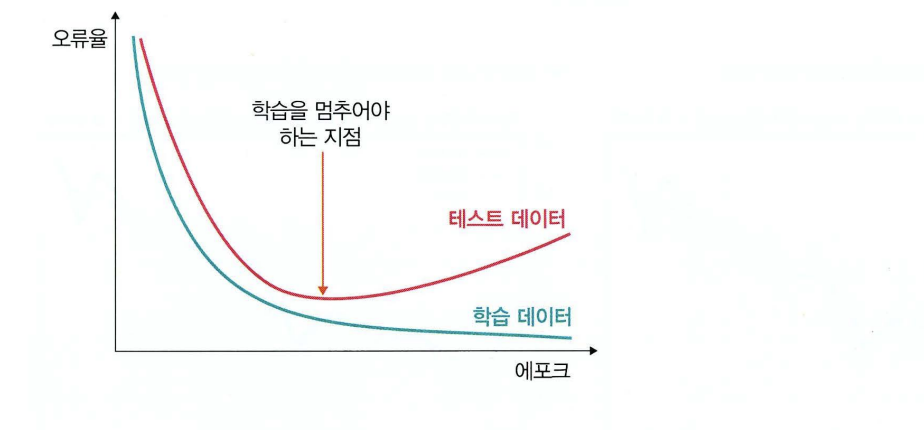

- 조기 종료는 학습을 언제 종료시킬지 결정할 뿐이지 최고의 성능을 갖는 모델을 보장하지는 않는다는 점에 주의

In [ ]:
# 라이브러리 호출
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models # 사전 학습된 모델을 이용하고자 할 때 사용하는 라이브러리
from torchvision import transforms, datasets

import matplotlib
import matplotlib.pyplot as plt
import time
import argparse
from tqdm import tqdm
matplotlib.style.use('ggplot') # 출력 그래프에서 격자로 숫자 범위가 눈에 잘 띄도록 하는 스타일
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [ ]:
# 데이터셋 전처리
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean = [0.485, 0.456, 0.406],
                         std = [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean = [0.485, 0.456, 0.406],
                         std = [0.229, 0.224, 0.225])
])

In [ ]:
!git clone https://github.com/gilbutITbook/080289.git

Cloning into '080289'...
remote: Enumerating objects: 2278, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 2278 (delta 3), reused 2 (delta 2), pack-reused 2262 (from 2)
Receiving objects: 100% (2278/2278), 330.29 MiB | 19.40 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Updating files: 100% (2591/2591), done.


In [ ]:
# 데이터셋 가져오기
train_dataset = datasets.ImageFolder(
    root=r'/content/080289/chap08/data/archive/train',
    transform = train_transform
)
train_dataloader = torch.utils.data.DataLoader(
    train_dataset, batch_size = 32, shuffle = True,
)
val_dataset = datasets.ImageFolder(
    root =r'/content/080289/chap08/data/archive/test',
    transform = val_transform
)
val_dataloader = torch.utils.data.DataLoader(
    val_dataset, batch_size = 32, shuffle = False,
)

In [ ]:
# 모델 생성
def resnet50(pretrained=True, requires_grad=False):
  model = models.resnet50(progress=True, pretrained=pretrained)
  if requires_grad == False: # 파라미터를 고정하여 backward() 중에 기울기가 계산되지 않도록 합니다. requires_grad = False를 파라미터로 받았기 때문에 해당 구문이 실행됩니다.
    for param in model.parameters():
      param.requires_grad = False
  elif requires_grad == True: # 파라미터 값이 backward() 중에 기울기 계산에 반영됩니다.
    for param in model.parameters():
      param.requires_grad = True

  model.fc = nn.LInear(2048, 2) # 마지막 분류를 위한 계층은 학습을 진행합니다.
  return model

- 파이토치에서 조기 종료와 함께 자주 사용되는 것이 '학습률 감소'
- 학습률에 대한 값을 고정시켜서 모델을 학습시키는 것이 아니라 학습이 진행되는 과정에서 학습률을 조금씩 낮추어 주는 성능 튜닝 기법 중 하나
- 학습률 감소는 '학습률 스케줄러'라는 것을 이용하는데, 주어진 'patience' 횟수만큼 검증 데이터셋에 대한 오차 감소가 없으면 역시 주어진 'factor'만큼 학습률을 감소시켜 모델 학습의 최적화가 가능하도록 도와줌

In [ ]:
from torch.optim import optimizer
# 학습률 감소
class LRScheduler():
  def __init__(
      self, optimizer, patience = 5, min_lr = 1e-6, factor = 0.5
  ):
      self.optimizer = optimizer
      self.patience = patience
      self.min_lr = min_lr
      self.factor = factor
      self.lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
          self.optimizer,
          mode = 'min',
          patience = self.patience,
          factor = self.factor,
          min_lr = self.min_lr,
          verbose = True
      )

  def __call__(self, val_loss):
    self.lr_scheduler.step(val_loss)


```
torch.optim.lr_scheduler.ReduceLROnPlateau(
          self.optimizer,
          mode = 'min',
          patience = self.patience,
          factor = self.factor,
          min_lr = self.min_lr,
          verbose = True
      )
```

- lr_scheduler.ReduceLROnPlateau: ReduceLROnPlateau는 검증 데이터셋에 대한 오차의 변동이 없으면 학습률을 factor배로 감소시킴
- mode: 언제 학습률을 조정할지에 대한 기준이 되는 값
- patience: 학습률을 업데이트하기 전에 몇 번의 에포크를 기다려야 하는지 결정하는 것
- factor: 학습률을 얼마나 감소시킬지 지정하는 파라미터
- min_lr: 학습률의 하한선 지정
- verbose: 조기 종료의 시작과 끝을 출력하기 위해 사용. 1로 설정할 경우 조기 종료가 적용되면 적용되었다고 화면에 출력


In [ ]:
# 조기 종료
class EarlyStopping():
  def __init__(self, patience = 5, verbose=False, delta=0,
               path = '/content/080289/chap08/data/checkpoint.pt'):
    self.patience = patience
    self.verbose = verbose
    self.coutner = 0
    self.best_score = None # 검증 데이터셋에 대한 오차 최적화 값
    self.early_stop = False # 조기 종료를 의미하며 초깃값은 False로 설정
    self.val_loss_min = np.Inf # np.Inf(infinity)는 넘파이에서 무한대를 표현
    self.delta = delta
    self.path = path # 모델이 저장될 경로

  def __call__(self, val_loss, model): # 에포크만큼 학습이 반복되면서 best_loss가 갱신되고, best_loss에 진전이 없으면 조기 종료한 후 모델을 저장
    score = -val_loss
    if self.best_score is None: # best_score에 값이 존재하지 않으면 실행
      self.best_score = score
      self.save_checkpoint(val_loss, model)
    elif score < self.best_score + self.delta: # vest_score + delta가 score보다 크면 실행
      self.counter += 1
      print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
      if self.counter >= self.patience:
        self.early_stop = True
    else: # 그 외 모든 경우에 실행
      self.best_score = score
      self.save_checkpoint(val_loss, model)
      self.counter = 0

  def save_checkpoint(self, val_loss, model): # 검증 데이터셋에 대한 오차가 감소하면 모델을 저장
    if self.verbose:
      print(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}). Saving model...')
    torch.save(model.state_dict(), self.path) # 지정된 경로에 모델 저장
    self.val_loss_min = val_loss

- patience: 오차 개선이 없다고 바로 종료하지 않고 개선이 없는 에포크를 얼마나 기다려 줄지 지정
- delta: 오차가 개선되고 있다고 판단하기 위한 최소 변화량

<br>

- 함수에 넘겨주는 인수 값에 따라 다른 동작을 하도록 해야 하는데, 이때 사용할 수 있는 것이 argparse 라이브러리.
- ArgumentParser()를 이용하여 변수와 타입을 정의해주고 add_argument()를 이용해서 변수에 인수 값을 하나씩 추가.
- parse_args()를 통해 사용자로부터 입력받은 값들을 args 변수에 저장

In [ ]:
# 인수 값 지정
parser = argparse.ArgumentParser() # 인수 값을 받을 수 있는 인스턴스 생성
parser.add_argument('--lr-scheduler', dest = 'lr_scheduler', action = 'store_true')
parser.add_argument('--early-stopping', dest = 'early_stopping', action = 'store_true') # 조기 종료에 대한 인수
args, unknown = parser.parse_known_args()
args = vars(args)

- dest: 입력 값이 저장되는 변수
- action: store_true로 지정하면 입력 값을 dest 파라미터에 의해 생성된 변수에 저장

In [ ]:
# 사전 훈련된 모델의 파라미터 확인
print(f"Computation device: {device}\n") # CPU를 사용하는지 GPU를 사용하는지 검사
model = models.resnet50(pretrained=True).to(device) # 사전 훈련된 ResNet50 사용
total_params = sum(p.numel() for p in model.parameters()) # 총 파라미터 수
print(f"{total_params:,} total parameters.")
total_trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad) # 학습 가능한 파라미터 수
print(f"{total_trainable_params:,} training parameters.")

Computation device: cuda:0



/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 177MB/s]


25,557,032 total parameters.
25,557,032 training parameters.


In [ ]:
# 옵티마이저와 손실 함수 지정
lr = 0.001
epochs = 100
optimizer = optim.Adam(model.parameters(), lr = lr)
criterion = nn.CrossEntropyLoss()

In [ ]:
# 오차, 정확도 및 모델의 이름에 대한 문자열
loss_plot_name = 'loss' # 오차 출력에 대한 문자열
acc_plot_name = 'accuracy' # 정확도 출력에 대한 문자열
model_name = 'model' # 모델을 저장하기 위한 문자열

In [ ]:
# 오차, 정확도 및 모델의 이름에 대한 문자열
if args['lr_scheduler']:
  print('INFO: Initializing learning rate scheduler')
  lr_scheduler = LRScheduler(optimizer)
  loss_plot_name = 'lrs_loss' # 학습률 감소를 적용했을 때의 오차에 대한 문자열
  acc_plt_name = 'lrs_accuracy' # 학습률 감소를 적용했을 때의 정확도에 대한 문자열
  model_name = 'lrs_model' # 학습률 감소를 적용했을 때의 모델에 대한 문자열
if args['early_stopping']:
  print('INFO: Initializing early stopping')
  early_stopping = EarlyStopping()
  loss_plot_name = 'es_loss' # 조기 종료를 적용했을 때의 오차에 대한 문자열
  acc_plot_name = 'es_accuracy' # 조기 종료를 적용했을 때의 정확도에 대한 문자열
  model_name = 'es_model' # 조기 종료를 적용했을 때의 모델에 대한 문자열

In [ ]:
# 모델 학습 함수
def training(model, train_dataloader, train_dataset, optimizer, criterion):
  print('Training')
  model.train()
  train_running_loss = 0.0
  train_running_correct = 0
  counter = 0
  total = 0
  prog_bar = tqdm(enumerate(train_dataloader), total = int(len(train_dataset)/
                                                           train_dataloader.batch_size)) # 훈련 진행 과정을 시각적으로 표현
  for i, data in prog_bar:
    counter += 1
    data, target = data[0].to(device), data[1].to(device)
    total += target.size(0)
    optimizer.zero_grad()
    outputs = model(data)
    loss = criterion(outputs, target)
    train_running_loss += loss.item()
    _, preds = torch.max(outputs.data, 1)
    train_running_correct += (preds == target).sum().item()
    loss.backward()
    optimizer.step()

  train_loss = train_running_loss / counter
  train_accuracy = 100. * train_running_correct / total
  return train_loss, train_accuracy

In [ ]:
# 모델 검증 함수
def validate(model, test_dataloader, val_dataset, criterion):
  print('Validating')
  model.eval()
  val_running_loss = 0.0
  val_running_correct = 0
  counter = 0
  total = 0
  prog_bar = tqdm(enumerate(test_dataloader), total=int(len(val_dataset)/
                                                        test_dataloader.batch_size)) # 모델 검증 과정을 시각적으로 표현
  with torch.no_grad():
    for i, data in prog_bar:
      counter += 1
      data, target = data[0].to(device), data[1].to(device)
      total += target.size(0)
      outputs = model(data)
      loss = criterion(outputs, target)

      val_running_loss += loss.item()
      _, preds = torch.max(outputs.data, 1)
      val_running_correct += (preds == target).sum().item()

    val_loss = val_running_loss / counter
    val_accuracy = 100. * val_running_correct / total
    return val_loss, val_accuracy

In [ ]:
# 모델 학습
train_loss, train_accuracy = [], [] # 훈련 데이터셋을 이용한 모델 학습 결과(오차, 정확도)를 저장하기 위한 변수(리스트 형태를 갖습니다)
val_loss, val_accuracy = [], [] # 검증 데이터셋을 이용한 모델 성능 결과(오차, 정확도)를 저장하기 위한 변수(리스트 형태를 갖습니다)

start = time.time()
for epoch in range(epochs):
  print(f"Epoch {epoch+1} of {epochs}")
  train_epoch_loss, train_epoch_accuracy = training(
      model, train_dataloader, train_dataset, optimizer, criterion
  )
  val_epoch_loss, val_epoch_accuracy = validate(
      model, val_dataloader, val_dataset, criterion
  )
  train_loss.append(train_epoch_loss)
  train_accuracy.append(train_epoch_accuracy)
  val_loss.append(val_epoch_loss)
  val_accuracy.append(val_epoch_accuracy)
  if args['lr_scheduler']: # 인수 값이 lr_scheduler이면 다음을 실행
    lr_scheduler(val_epoch_loss)
  if args['early_stopping']: # 인수 값이 early_stopping이면 다음을 실행
    early_stopping(val_epoch_loss, model)
    if early_stopping.early_stop:
      break
  print(f"Train Loss: {train_epoch_loss:.4f}, Train Acc: {train_epoch_accuracy:.2f}")
  print(f"Val Loss: {val_epoch_loss:.4f}, Val Acc: {val_epoch_accuracy:.2f}")
  end = time.time()
  print(f"Training time: {(end-start)/60:.3f} minutes")

Epoch 1 of 100
Training


16it [06:25, 24.12s/it]


Validating


16it [01:42,  6.38s/it]


Train Loss: 2.3444, Train Acc: 58.03
Val Loss: 10.8561, Val Acc: 51.60
Training time: 8.133 minutes
Epoch 2 of 100
Training


16it [06:04, 22.75s/it]


... (190 outputs left out)

Train Loss: 0.0783, Train Acc: 97.39
Val Loss: 0.6877, Val Acc: 79.20
Training time: 383.235 minutes
Epoch 50 of 100
Training


16it [05:58, 22.41s/it]


Validating


 47%|████▋     | 7/15 [00:45<00:51,  6.48s/it]

Saving loss and accuracy plots...


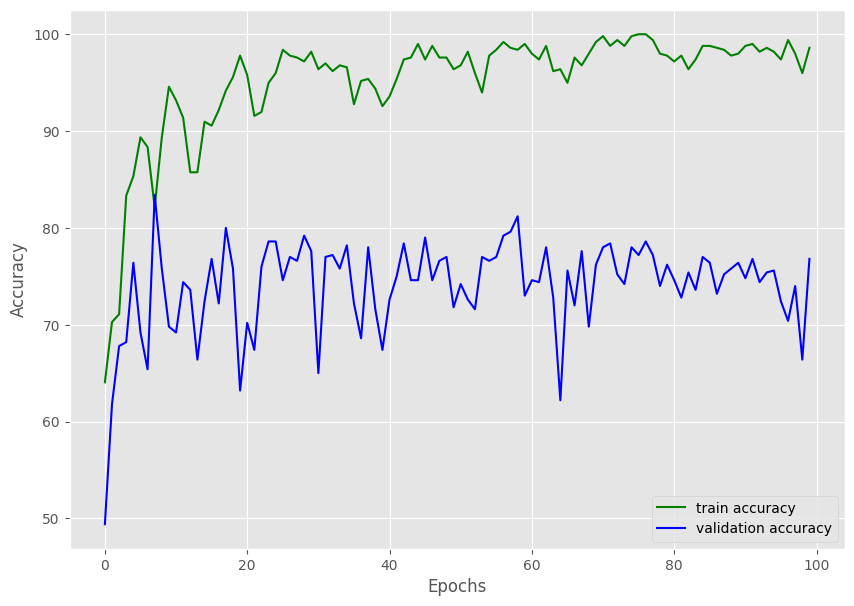

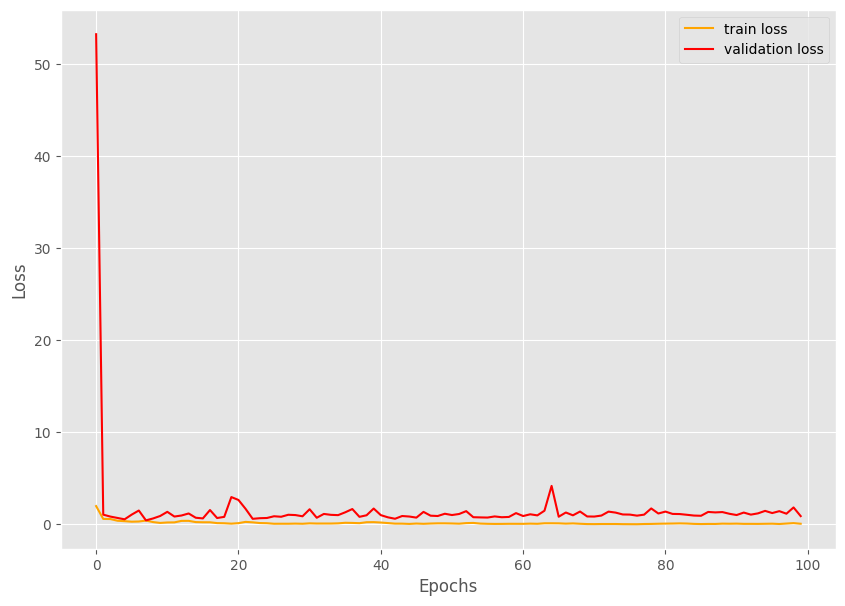

Saving model...
TRAINING COMPLETE


In [ ]:
# 모델 학습 결과 출력
print('Saving loss and accuracy plots...')
plt.figure(figsize = (10, 7))
plt.plot(train_accuracy, color = 'green', label = 'train accuracy') # 훈련 데이터셋에 대한 정확도를 그래프로 출력
plt.plot(val_accuracy, color = 'blue', label = 'validation accuracy') # 검증 데이터셋에 대한 정확도를 그래프를 출력
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig(f'/content/080289/chap08/data/{acc_plot_name}.png')
plt.show()
plt.figure(figsize = (10, 7))
plt.plot(train_loss, color = 'orange', label = 'train loss') # 훈련 데이터셋에 대한 오차를 그래프로 출력
plt.plot(val_loss, color = 'red', label = 'validation loss') # 검증 데이터셋에 대한 오차를 그래프로 출력
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig(f'/content/080289/chap08/data/{loss_plot_name}.png')
plt.show()

print('Saving model...')
torch.save(model.state_dict(), f'/content/080289/chap08/data/{model_name}.pth') # 모델을 저장
print('TRAINING COMPLETE')